# Análise — idade de pico no 50m livre masculino (2010–2025)

Especificação principal (N = 50)
1. mantém as N primeiras posições de cada ano
2. remove linhas sem ano de nascimento
3. desempenho = tempo ÷ mediana do top 50 do ano (tempo relativo; menor = melhor) em que o denominador é sempre o top 50, qualquer que seja N
4. pico = ano com menor tempo relativo de cada atleta
5. só atletas com ≥ 4 anos na lista
6. exclui atletas cujo pico caiu em 2010 ou 2025 (borda da janela)

Incerteza: intervalo de confiança de 95% por bootstrap (10 000 reamostragens dos atletas)
Sensibilidade: variantes de filtros e listas com N = 100 e N = 200. Temporada = ano civil

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

FIG = Path("figuras"); FIG.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 8, "figure.dpi": 150})
LARGURA = 3.5 

bruto = pd.read_csv("data/ranking_50livre_M_2010_2025.csv")   # até ~200 posições por ano
df = bruto.dropna(subset=["ano_nascimento"]).copy()

mediana_ano = df[df["posicao"] <= 50].groupby("ano")["tempo_s"].median()
df["tempo_rel"] = df["tempo_s"] / df["ano"].map(mediana_ano)
print(f"Posição máxima nos dados: {bruto['posicao'].max()}")
mediana_ano.round(2)

Posição máxima nos dados: 200


ano
2010    22.34
2011    22.19
2012    22.04
2013    22.01
2014    22.10
2015    22.08
2016    22.02
2017    21.99
2018    22.00
2019    21.96
2020    22.10
2021    21.96
2022    21.91
2023    21.87
2024    21.81
2025    21.78
Name: tempo_s, dtype: float64

## Funções

In [8]:
def picos_e_funil(N=50, min_anos=4, tirar_borda=True, coluna="tempo_rel", dados=None):
    dados = df if dados is None else dados
    funil = {"registros": int((bruto["posicao"] <= N).sum())}
    d = dados[dados["posicao"] <= N]
    funil["com nascimento"] = len(d)
    funil["atletas"] = d["atleta_id"].nunique()

    anos_por_atleta = d.groupby("atleta_id")["ano"].nunique()
    d = d[d["atleta_id"].isin(anos_por_atleta[anos_por_atleta >= min_anos].index)]
    funil[f">= {min_anos} anos"] = d["atleta_id"].nunique()

    picos = d.loc[d.groupby("atleta_id")[coluna].idxmin()]
    if tirar_borda:
        picos = picos[~picos["ano"].isin([2010, 2025])]
    funil["amostra final"] = len(picos)
    return picos, funil

def ic95(idades, estatistica=np.median, B=10_000, seed=0):
    rng = np.random.default_rng(seed)
    a = np.asarray(idades)
    reps = [estatistica(rng.choice(a, len(a))) for _ in range(B)]
    return np.percentile(reps, [2.5, 97.5])

def resumo(picos):
    i = picos["idade"]
    lo, hi = ic95(i)
    return {"n": len(i), "média": round(float(i.mean()), 1), "mediana": float(i.median()),
            "Q1": float(i.quantile(0.25)), "Q3": float(i.quantile(0.75)),
            "IC95 mediana": f"{lo:.0f}–{hi:.0f}"}

## Resultado principal (N = 50)

In [9]:
picos, funil = picos_e_funil()
i = picos["idade"]
print(resumo(picos))
print("IC95 da média:", np.round(ic95(i, np.mean), 1))
print(f"Entre 22 e 27 anos: {((i >= 22) & (i <= 27)).mean():.0%} | entre 21 e 27: {((i >= 21) & (i <= 27)).mean():.0%}")
print(f"Idade mais frequente: {i.mode()[0]:.0f} ({(i == i.mode()[0]).sum()} atletas)")

{'n': 65, 'média': 24.8, 'mediana': 24.0, 'Q1': 22.0, 'Q3': 27.0, 'IC95 mediana': '23–26'}
IC95 da média: [24.  25.6]
Entre 22 e 27 anos: 62% | entre 21 e 27: 74%
Idade mais frequente: 22 (14 atletas)


## Funil de seleção (Tabela I do artigo)

In [10]:
funis = pd.DataFrame({f"N = {N}": picos_e_funil(N=N)[1] for N in (50, 100, 200)})
display(funis)
for etapa, linha in funis.iterrows():  
    print(f"{etapa} & " + " & ".join(str(v) for v in linha) + r" \\")

,N = 50,N = 100,N = 200
registros,809,1619,3200
com nascimento,806,1614,3189
atletas,253,496,1043
>= 4 anos,77,168,313
amostra final,65,142,270


registros & 809 & 1619 & 3200 \\
com nascimento & 806 & 1614 & 3189 \\
atletas & 253 & 496 & 1043 \\
>= 4 anos & 77 & 168 & 313 \\
amostra final & 65 & 142 & 270 \\


## Sensibilidade (Tabela II do artigo)

In [11]:
variantes = {
    "Principal": picos_e_funil()[0],
    "Mínimo de 3 anos": picos_e_funil(min_anos=3)[0],
    "Mínimo de 5 anos": picos_e_funil(min_anos=5)[0],
    "Sem filtro de borda": picos_e_funil(tirar_borda=False)[0],
    "Sem 2020": picos_e_funil(dados=df[df["ano"] != 2020])[0],
    "Sem parciais": picos_e_funil(dados=df[~df["split"]])[0],
    "Tempo absoluto": picos_e_funil(coluna="tempo_s")[0],
    "Top 100": picos_e_funil(N=100)[0],
    "Top 200": picos_e_funil(N=200)[0],
}
tabela = pd.DataFrame({nome: resumo(p) for nome, p in variantes.items()}).T
display(tabela)

fmt = lambda x: f"{x:g}".replace(".", ",")
for nome, r in tabela.iterrows():   # linhas prontas para o LaTeX
    print(f"{nome} & {r['n']} & {fmt(r['média'])} & {fmt(r['mediana'])} & "
          f"{fmt(r['Q1'])}--{fmt(r['Q3'])} & {r['IC95 mediana'].replace('–', '--')} \\\\")

,n,média,mediana,Q1,Q3,IC95 mediana
Principal,65,24.8,24.0,22.0,27.0,23–26
Mínimo de 3 anos,93,24.3,24.0,22.0,26.0,23–25
Mínimo de 5 anos,45,25.3,25.0,22.0,28.0,24–26
Sem filtro de borda,77,24.8,24.0,22.0,27.0,23–26
Sem 2020,59,24.8,24.0,22.0,27.5,23–26
Sem parciais,65,24.8,24.0,22.0,27.0,23–26
Tempo absoluto,67,25.5,25.0,23.0,27.5,24–26
Top 100,142,23.9,24.0,22.0,26.0,23–24
Top 200,270,23.6,23.0,22.0,25.0,23–24


Principal & 65 & 24,8 & 24 & 22--27 & 23--26 \\
Mínimo de 3 anos & 93 & 24,3 & 24 & 22--26 & 23--25 \\
Mínimo de 5 anos & 45 & 25,3 & 25 & 22--28 & 24--26 \\
Sem filtro de borda & 77 & 24,8 & 24 & 22--27 & 23--26 \\
Sem 2020 & 59 & 24,8 & 24 & 22--27,5 & 23--26 \\
Sem parciais & 65 & 24,8 & 24 & 22--27 & 23--26 \\
Tempo absoluto & 67 & 25,5 & 25 & 23--27,5 & 24--26 \\
Top 100 & 142 & 23,9 & 24 & 22--26 & 23--24 \\
Top 200 & 270 & 23,6 & 23 & 22--25 & 23--24 \\


## Figura 1 — distribuição das idades de pico (N = 50)

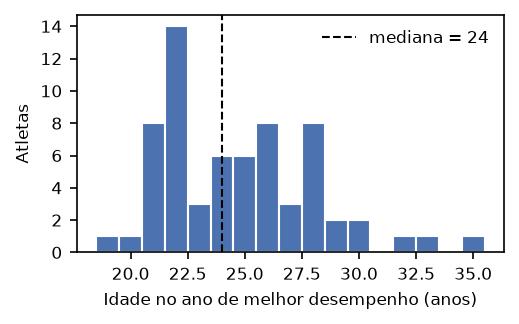

In [12]:
fig, ax = plt.subplots(figsize=(LARGURA, 2.2))
bins = range(int(i.min()), int(i.max()) + 2)
ax.hist(i, bins=bins, align="left", color="#4C72B0", edgecolor="white")
ax.axvline(i.median(), color="black", ls="--", lw=1, label=f"mediana = {i.median():.0f}")
ax.set_xlabel("Idade no ano de melhor desempenho (anos)")
ax.set_ylabel("Atletas")
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "hist_idade_pico.pdf")
plt.show()

# O ano de pico dos atletas da amostra principal muda ao ampliar a lista?

In [13]:
p50 = picos_e_funil(N=50)[0].set_index("atleta_id")["ano"]
for N in (100, 200):
    pN = picos_e_funil(N=N)[0].set_index("atleta_id")["ano"]
    comuns = p50.index.intersection(pN.index)
    iguais = (p50[comuns] == pN[comuns]).mean()
    print(f"N = {N}: {len(comuns)} de {len(p50)} atletas presentes; ano de pico igual em {iguais:.0%}")

N = 100: 65 de 65 atletas presentes; ano de pico igual em 100%
N = 200: 65 de 65 atletas presentes; ano de pico igual em 100%
